# Etapa 1. Preprocesamiento por lotes (ordenación y búsqueda binaria)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 0, 1 y 2: Cristina.

## Función de la etapa en el pipeline

La etapa 1 recibe los micro-lotes de registros crudos que entrega la etapa 0 y devuelve lotes de eventos limpios. Un evento limpio cumple el esquema, tiene sus campos en un formato único, no está repetido y está ordenado por tiempo. Las etapas siguientes pueden confiar en esos datos sin volver a revisarlos.

El enunciado asigna a esta etapa dos herramientas, la **ordenación eficiente** y la **búsqueda binaria**. Ambas se implementan a mano. `sorted`, `bisect` y `set` se usan solo como líneas base de comparación. El código de la etapa está en `src/etapa_1/preprocess.py`; el notebook lo importa y muestra cada parte junto a su explicación.

## Proceso de cada lote

```
lote crudo (etapa 0)
   │
   ├─ 1. validar el esquema ──────────► cola de rechazados (con motivo)
   ├─ 2. normalizar campos
   ├─ 3. ordenar por (clave, ts) con merge sort y eliminar duplicados adyacentes   O(b log b)
   ├─ 4. eliminar duplicados de lotes anteriores con búsqueda binaria              O(b log w)
   └─ 5. reordenar por ts con merge sort                                           O(b log b)
   │
lote limpio (etapa 2)
```

Aquí b es el tamaño del lote y w el tamaño de la ventana de claves recientes.

La deduplicación de esta etapa es **determinista**: decide comparando las claves completas y no sus hashes, así que no tiene los falsos positivos por colisión de un filtro probabilístico. Su límite está en la definición de duplicado, la misma clave a 1 s o menos, que también cumplen algunos eventos legítimos. El paso 8 mide esa pérdida, que es del 0.24 % de los eventos. La deduplicación probabilística con Bloom Filter corresponde a la etapa 6, y las dos no se solapan. La etapa 1 limpia duplicados técnicos, como reenvíos y reintentos, dentro de una ventana corta. La etapa 6 responde a otra pregunta, si una tarjeta, cuenta o dispositivo ya fue visto alguna vez, con memoria acotada sobre todo el stream.

## Pasos del notebook

1. Configuración y lectura de la salida de la etapa 0.
2. Contrato de evento y cola de rechazados.
3. Validación del esquema y normalización.
4. Merge sort propio.
5. Deduplicación dentro del lote (ordenar y recorrer).
6. Deduplicación entre lotes (ventana ordenada y búsqueda binaria).
7. Reordenación por tiempo.
8. Ejecución de la etapa 1 sobre todos los lotes y verificación.
9. Experimentos de complejidad de la ordenación, la búsqueda y la deduplicación.
10. Salida de la etapa 1 para la etapa 2.

## Paso 1. Configuración y entrada

La entrada son los archivos que generó el notebook de la etapa 0 en `data/interim/<CATEGORIA>/`. La categoría y las rutas se toman de `src/config.py`, igual que en la etapa 0. Los resultados de los experimentos se guardan en `results/etapa_1/`. La celda muestra al final la plataforma y la semilla, que el enunciado pide reportar junto con los tiempos.

- `etapa0_lotes.jsonl` tiene una línea por micro-lote con sus registros crudos.
- `etapa0_inyecciones.json` tiene los conteos del ruido inyectado. Son la verdad de referencia para comprobar que esta etapa detecta lo que debe.

Los lotes se leen con un generador, uno a la vez, igual que si llegaran del buffer de la etapa 0.

In [1]:
import bisect                     # línea base de la búsqueda binaria propia
import gc
import inspect
import json
import platform
import random
import sys
import time
import tracemalloc
from array import array
from collections import Counter
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_1"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

RUTA_LOTES_ETAPA0 = CARPETA_INTERIM / "etapa0_lotes.jsonl"
RUTA_INYECCIONES = CARPETA_INTERIM / "etapa0_inyecciones.json"
assert RUTA_LOTES_ETAPA0.exists(), "Falta la salida de la etapa 0. Ejecutar antes notebooks/etapa0_ingesta_buffer.ipynb"

inyecciones = json.loads(RUTA_INYECCIONES.read_text(encoding="utf-8"))

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}


def leer_lotes(ruta):
    """Entrega (numero_lote, registros) uno a la vez, sin cargar el archivo completo."""
    with open(ruta, "r", encoding="utf-8") as archivo:
        for linea in archivo:
            lote = json.loads(linea)
            yield lote["lote"], lote["registros"]


n_lotes = n_registros = 0
for _, registros in leer_lotes(RUTA_LOTES_ETAPA0):
    n_lotes += 1
    n_registros += len(registros)
print(f"Categoría: {CATEGORIA}")
print(f"Entrada: {n_lotes} lotes, {n_registros:,} registros crudos")
print("Ruido inyectado por la etapa 0:",
      {k: inyecciones[k] for k in ["duplicados_exactos", "duplicados_casi", "malformados", "tardios"]})
PLATAFORMA

Categoría: Office_Products
Entrada: 21025 lotes, 10,512,167 registros crudos
Ruido inyectado por la etapa 0: {'duplicados_exactos': 299972, 'duplicados_casi': 149241, 'malformados': 100629, 'tardios': 502881}


{'sistema': 'Windows-11-10.0.26300-SP0',
 'procesador': 'Intel64 Family 6 Model 151 Stepping 2, GenuineIntel',
 'nucleos': 20,
 'ram_gb': 34.0,
 'python': '3.12.0',
 'semilla': 42}

## Paso 2. Contrato de evento y cola de rechazados

### Contrato de evento

`Event` es el formato que comparten todas las etapas del pipeline y está definido en `src/events.py`. La etapa 1 es la primera que lo produce. Además de los campos que describen el evento, tiene cinco campos que usan etapas posteriores.

| Campo | Para qué se usa |
| --- | --- |
| `category` | Categoría canónica del producto, para las consultas de la etapa 3 y la similitud de la etapa 7 |
| `query` | Texto de búsqueda, para el autocompletado (Trie) de la etapa 9 |
| `rating` | Calificación de las reseñas |
| `priority`, `deadline` | Quedan vacíos en esta etapa y los asigna la etapa 2 |

`slots=True` hace que cada evento ocupe menos memoria, porque Python no crea un diccionario interno por objeto.

### Cola de rechazados

Los registros inválidos no se descartan en silencio. Pasan a una cola de rechazados junto con el motivo, y un contador registra cuántos hay de cada tipo. Así se pueden auditar o reprocesar después. Se usa la `ColaEnlazada` de la etapa 0 (`src/etapa_0/queue.py`, explicada en el paso 5 de ese notebook) porque esta cola no debe tener límite, ya que perder un rechazo impediría auditarlo.

La celda siguiente importa las dos estructuras y muestra el código de `Event`.

In [2]:
from src.events import Event
from src.etapa_0.queue import ColaEnlazada

print(inspect.getsource(Event))

@dataclass(slots=True)
class Event:
    event_id: str
    event_type: str            # search | view | cart | purchase | review | return | payment_alert
    user_id: str
    parent_asin: str | None    # None en las búsquedas
    order_id: str | None
    order_type: str | None     # express | standard | scheduled
    price: float | None
    payment_id: str | None
    device_id: str | None
    ts: float                  # segundos Unix
    category: str | None = None     # categoría canónica (etapas 3 y 7)
    query: str | None = None        # texto de búsqueda (autocompletado, etapa 9)
    rating: float | None = None     # solo en reseñas
    priority: int | None = None     # lo asigna la etapa 2
    deadline: float | None = None   # lo asigna la etapa 2



## Paso 3. Validación y normalización

Cada registro se revisa campo por campo. Si una regla no se cumple, el registro se rechaza con el motivo correspondiente. Si todas se cumplen, se crea un `Event` con los campos normalizados. Validar y normalizar ocurren en el mismo recorrido porque muchas reglas solo se pueden revisar después de normalizar. Por ejemplo, un precio `"$19.99"` solo se puede comprobar como positivo después de convertirlo a número.

| Campo | Regla de validación | Normalización |
| --- | --- | --- |
| `event_type` | Debe ser uno de los 7 tipos conocidos | Minúsculas y sin espacios |
| `user_id` | Obligatorio y no vacío | Sin espacios y en mayúsculas, como en el dataset |
| `ts` | Número entre los años 2000 y 2100 | Milisegundos a segundos (si es mayor que 10¹¹ está en ms) |
| `parent_asin` | Obligatorio salvo en `search` | Sin espacios y en mayúsculas; vacío en `search` pasa a `None` |
| `order_id` | Obligatorio en `cart`, `purchase`, `return` y `payment_alert` | Sin espacios |
| `order_type` | Si existe, debe ser `express`, `standard` o `scheduled`; obligatorio en `purchase` | Minúsculas |
| `price` | Obligatorio en `purchase`; si existe, debe ser un número positivo | Se toma el primer número del texto: `"$19.99"`, `"19,99"` y `"19.99"` pasan a `19.99`, `"from 14.99"` pasa a `14.99` y `"$1,299.00"` a `1299.0`; `"—"`, `"None"`, vacío o un texto sin dígitos pasan a `None` |
| `rating` | Obligatorio en `review`, entre 1 y 5 | Número real |
| `category` | Opcional | Forma canónica, por ejemplo `"  OFFICE products "` pasa a `office_products` |
| `query` | Opcional | Minúsculas y espacios simples |

El precio llega como texto crudo del catálogo, que mezcla números, nulos, textos como `"from 14.99"` y guiones (`"—"`). Una compra cuyo precio no contiene ningún número se rechaza por `precio_invalido`, porque una compra exige precio.

El rechazo es una decisión conservadora. Un registro sin `user_id` o con `ts` inválido no se puede reparar sin inventar datos, y un dato inventado contaminaría el ranking, el fraude y el grafo de las etapas siguientes.

### Implementación

Las reglas están en `src/etapa_1/preprocess.py`. La celda siguiente importa la conversión del precio y la validación, y muestra su código.

In [3]:
from src.etapa_1.preprocess import normalizar_precio, validar_y_normalizar

print(inspect.getsource(normalizar_precio))
print(inspect.getsource(validar_y_normalizar))

def normalizar_precio(valor):
    """Convierte el precio crudo a float, o a None si no contiene ningún número.

    El catálogo mezcla formatos: "2.68", None, "from 14.99", "—", "$1,299.00" y, en los
    duplicados sintéticos, "19,99". Se toma el primer número del texto:
    - "from 14.99" -> 14.99 y "14.99 - 29.99" -> 14.99 (precio desde);
    - una coma seguida de exactamente dos dígitos al final es decimal: "19,99" -> 19.99;
    - cualquier otra coma es de miles: "1,299.00" -> 1299.0;
    - "—", "", "None" o un texto sin dígitos -> None.
    El signo se conserva para que un precio negativo se rechace en la validación.
    """
    if valor is None:
        return None
    if isinstance(valor, (int, float)) and not isinstance(valor, bool):
        return float(valor)
    texto = str(valor).strip().replace("$", "")
    if texto.lower() in {"", "none", "null", "nan"}:
        return None
    coincidencia = _NUMERO.search(texto)
    if coincidencia is None:
        return None           

### Ejemplos

Se aplican las reglas a registros de prueba. El primero es correcto pero tiene formatos variados, y los demás tienen un error cada uno.

In [4]:
base = {"event_id": "e1", "event_type": " PURCHASE ", "user_id": " agkhlew2sowhnmfqijgbecaf7inq",
        "parent_asin": "b00yq6x8eo", "order_id": "o1", "order_type": "Express", "price": "$19,99",
        "payment_id": "pay_1", "device_id": "dev_1", "ts": 1672531800123,
        "category": "  OFFICE products ", "query": None, "rating": None}

ejemplos = {
    "correcto con formatos variados": base,
    "sin user_id": {**base, "user_id": None},
    "ts inválido": {**base, "ts": "2023-13-45T99:99"},
    "tipo desconocido": {**base, "event_type": "clik"},
    "compra sin producto": {**base, "parent_asin": ""},
    "precio negativo": {**base, "price": "-12.50"},
    "precio 'from 14.99' (válido)": {**base, "price": "from 14.99"},
    "compra con precio '—'": {**base, "price": "—"},
    "búsqueda sin producto (válida)": {**base, "event_type": "search", "parent_asin": "", "order_id": None,
                                       "order_type": None, "price": None, "query": "  Yes To  TOMATOES"},
}
for nombre, registro in ejemplos.items():
    evento, motivo = validar_y_normalizar(registro)
    print(f"{nombre:32} -> {'RECHAZADO: ' + motivo if motivo else evento}")

correcto con formatos variados   -> Event(event_id='e1', event_type='purchase', user_id='AGKHLEW2SOWHNMFQIJGBECAF7INQ', parent_asin='B00YQ6X8EO', order_id='o1', order_type='express', price=19.99, payment_id='pay_1', device_id='dev_1', ts=1672531800.123, category='office_products', query=None, rating=None, priority=None, deadline=None)
sin user_id                      -> RECHAZADO: sin_user_id
ts inválido                      -> RECHAZADO: ts_invalido
tipo desconocido                 -> RECHAZADO: tipo_desconocido
compra sin producto              -> RECHAZADO: sin_parent_asin
precio negativo                  -> RECHAZADO: precio_invalido
precio 'from 14.99' (válido)     -> Event(event_id='e1', event_type='purchase', user_id='AGKHLEW2SOWHNMFQIJGBECAF7INQ', parent_asin='B00YQ6X8EO', order_id='o1', order_type='express', price=14.99, payment_id='pay_1', device_id='dev_1', ts=1672531800.123, category='office_products', query=None, rating=None, priority=None, deadline=None)
compra con precio 

## Paso 4. Merge sort propio

Merge sort aplica la estrategia divide y vencerás (Cormen et al., 2022, cap. 2).

1. **Dividir.** Parte la lista en dos mitades.
2. **Conquistar.** Ordena cada mitad de forma recursiva. Una lista de 0 o 1 elementos ya está ordenada.
3. **Combinar.** Mezcla las dos mitades ordenadas en una sola, comparando el primer elemento pendiente de cada una.

```
[5, 2, 4, 1]
 /         \
[5, 2]     [4, 1]          dividir
 / \        / \
[5] [2]    [4] [1]
 \ /        \ /
[2, 5]     [1, 4]          mezclar
 \         /
[1, 2, 4, 5]
```

### Complejidad

- **Tiempo O(n log n) en todos los casos.** El árbol de llamadas tiene log₂ n niveles y en cada nivel se mezclan n elementos en total.
- **Espacio O(n) adicional** para las listas de la mezcla.

### Por qué merge sort

- Su costo O(n log n) está garantizado también en el peor caso. Quicksort puede degradarse a O(n²) con datos ya ordenados, y los lotes llegan casi ordenados por tiempo.
- **Es estable.** Dos elementos con la misma clave conservan su orden original, porque en la mezcla gana el de la izquierda cuando hay empate (`<=`). En el paso 7 se ordena por `ts`, y los eventos con el mismo `ts`, como los productos de una misma orden, no cambian de posición relativa.
- Ordena cualquier clave comparable, como tuplas de texto.

Su desventaja es la memoria adicional O(n). Con lotes de 500 eventos esa memoria es despreciable.

### Implementación

`merge_sort(items, clave)` primero calcula la clave de cada elemento una sola vez y forma pares `(clave, elemento)`. Así la función de clave no se recalcula en cada comparación, y la mezcla compara solo la clave y nunca los elementos. El código está en `src/etapa_1/preprocess.py`. La celda siguiente lo importa, muestra su código y lo compara con `sorted()`.

In [5]:
from src.etapa_1.preprocess import _merge_sort_pares, _mezclar, merge_sort

print(inspect.getsource(merge_sort))
print(inspect.getsource(_merge_sort_pares))
print(inspect.getsource(_mezclar))

# Pruebas: se compara con sorted() en listas aleatorias y en casos borde
rng = random.Random(SEED)
for n in [0, 1, 2, 3, 10, 101, 1000]:
    datos = [rng.randint(0, 50) for _ in range(n)]
    assert merge_sort(datos) == sorted(datos)
assert merge_sort(list(range(100))) == list(range(100))            # ya ordenado
assert merge_sort(list(range(100, 0, -1))) == list(range(1, 101))  # orden inverso

# Estabilidad: con clave repetida se conserva el orden original
pares_prueba = [(1, "a"), (0, "b"), (1, "c"), (0, "d")]
assert merge_sort(pares_prueba, clave=lambda p: p[0]) == [(0, "b"), (0, "d"), (1, "a"), (1, "c")]
print("Todas las pruebas de merge sort pasaron.")

def merge_sort(items, clave=None):
    """Devuelve una lista nueva con items ordenados por clave(item). Estable. O(n log n)."""
    if clave is None:
        clave = lambda x: x
    pares = [(clave(x), x) for x in items]          # la clave se calcula una sola vez
    return [x for _, x in _merge_sort_pares(pares)]

def _merge_sort_pares(pares):
    if len(pares) <= 1:                             # caso base: ya está ordenado
        return pares
    medio = len(pares) // 2
    izquierda = _merge_sort_pares(pares[:medio])    # dividir y ordenar cada mitad
    derecha = _merge_sort_pares(pares[medio:])
    return _mezclar(izquierda, derecha)             # combinar

def _mezclar(izquierda, derecha):
    """Mezcla dos listas de pares ya ordenadas. O(len(izquierda) + len(derecha))."""
    resultado = []
    i = j = 0
    while i < len(izquierda) and j < len(derecha):
        if izquierda[i][0] <= derecha[j][0]:        # <= mantiene la estabilidad
            resultado.append(izquierda[i])


## Paso 5. Deduplicación dentro del lote

### Clave de deduplicación

Dos registros son duplicados si describen el mismo hecho, aunque su `event_id` o su formato sean distintos. La etapa 0 inyecta dos tipos de duplicados.

- **Exactos.** El mismo registro reenviado, con el mismo `event_id`.
- **Casi exactos.** Un reintento con otro `event_id`, un `ts` desplazado hasta 0.4 s, el `user_id` en minúsculas con un espacio y el precio en otro formato.

Por eso la clave no usa `event_id` y se calcula **después** de normalizar. Está formada por los campos que identifican el hecho.

```
clave = (event_type, user_id, parent_asin, order_id, query)
```

Dos eventos son duplicados si tienen la misma clave y sus `ts` difieren en 1 segundo o menos (`TOLERANCIA_S`). La tolerancia cubre el desplazamiento de los reintentos y es mucho menor que la separación entre eventos legítimos del mismo usuario, que es de minutos.

### Ordenar y recorrer

1. Se ordena el lote por `(clave, ts)` con merge sort, en O(b log b).
2. Después de ordenar, todos los duplicados de un evento quedan uno junto a otro.
3. Un solo recorrido lineal, en O(b), compara cada evento con el último que se conservó. Si tienen la misma clave y el `ts` está dentro de la tolerancia, el evento es un duplicado y se descarta.

```
ordenado por (clave, ts):
  (purchase, U1, B01, o7)  ts=100.0   ← se conserva
  (purchase, U1, B01, o7)  ts=100.3   ← duplicado (misma clave, 0.3 s)
  (view,     U1, B01, -)   ts= 40.0   ← se conserva (otra clave)
  (view,     U1, B01, -)   ts=310.0   ← se conserva (misma clave, pero 270 s después)
```

El costo total es O(b log b). La alternativa directa, comparar cada par de eventos, costaría O(b²). La alternativa con `set()` no admite la tolerancia de tiempo, porque un hash solo detecta claves idénticas y dos `ts` a 0.3 s de distancia tienen hashes distintos.

Se conserva siempre la copia con el `ts` más temprano, y se registra si cada duplicado era exacto (mismo `event_id`) o casi exacto. Ese registro permite comparar con lo que inyectó la etapa 0.

### Implementación

La función está en `src/etapa_1/preprocess.py`. Acepta un parámetro opcional, `al_descartar`, que avisa de cada duplicado descartado; lo usa la traza del visualizador y no cambia el resultado. La celda siguiente la importa, muestra su código y la prueba con el caso del diagrama.

In [6]:
from src.etapa_1.preprocess import TOLERANCIA_S, clave_dedup, deduplicar_lote

print(inspect.getsource(clave_dedup))
print(inspect.getsource(deduplicar_lote))

# Ejemplo con el caso del diagrama
def ev(event_id, tipo, ts, orden=None):
    return Event(event_id, tipo, "U1", "B01", orden, None, None, None, None, ts)

prueba = [ev("e1", "purchase", 100.0, "o7"), ev("e2", "view", 310.0), ev("e3", "purchase", 100.3, "o7"),
          ev("e4", "view", 40.0), ev("e1", "purchase", 100.0, "o7")]
unicos, exactos, casi = deduplicar_lote(prueba)
print([(e.event_id, e.event_type, e.ts) for e in unicos], f"exactos={exactos}, casi={casi}")
assert [e.event_id for e in unicos] == ["e1", "e4", "e2"] and (exactos, casi) == (1, 1)

def clave_dedup(e):
    """Campos que identifican el hecho. None se reemplaza por '' para poder comparar tuplas."""
    return (e.event_type, e.user_id, e.parent_asin or "", e.order_id or "", e.query or "")

def deduplicar_lote(eventos, tolerancia_s=TOLERANCIA_S, al_descartar=None):
    """Ordena por (clave, ts) y elimina duplicados adyacentes.

    Devuelve (unicos ordenados por clave y ts, numero de duplicados exactos, numero de casi exactos).
    al_descartar(descartado, conservado, tipo): función opcional que se llama con cada duplicado.
    """
    ordenados = merge_sort(eventos, clave=lambda e: (clave_dedup(e), e.ts))
    unicos = []
    exactos = casi = 0
    clave_anterior = None
    for e in ordenados:
        clave = clave_dedup(e)
        if unicos and clave == clave_anterior and e.ts - unicos[-1].ts <= tolerancia_s:
            tipo = "exacto" if e.event_id == unicos[-1].event_id else "casi"
            if tipo == "exacto":
                exactos += 1
            else:
   

## Paso 6. Deduplicación entre lotes con búsqueda binaria

Un duplicado puede llegar en un lote distinto del original. Por ejemplo, el original llega al final de un lote y el reenvío al inicio del siguiente. Para detectarlo, la etapa guarda una **ventana de claves recientes**.

### Estructura

La ventana es un arreglo ordenado de tuplas `(clave, ts, event_id)` con los eventos aceptados en los últimos `VENTANA_S` segundos de tiempo del evento. Se eligió un arreglo ordenado por tres motivos.

- Permite buscar con **búsqueda binaria** en O(log w).
- Ocupa poca memoria, una referencia por entrada.
- Se actualiza una vez por lote con una mezcla lineal, la misma operación que usa merge sort.

### Búsqueda

Para un evento con clave k y tiempo t, la búsqueda binaria encuentra la primera entrada mayor o igual que `(k, t − tolerancia)`. Si esa entrada tiene la misma clave y su `ts` es menor o igual que t + tolerancia, el evento ya fue visto y es un duplicado.

La búsqueda binaria compara el valor buscado con el elemento central del rango y descarta la mitad que no puede contenerlo. Cada paso reduce el rango a la mitad, así que se necesitan como máximo ⌈log₂(w + 1)⌉ comparaciones. Con w = 1 000 000 son 20 comparaciones, frente al millón que necesitaría una búsqueda lineal.

### Actualización por lote

1. Se descartan las entradas con `ts` menor que `ts_max − VENTANA_S`, donde `ts_max` es el mayor `ts` visto.
2. Se mezclan las entradas que quedan con las del lote nuevo, que ya están ordenadas por el paso 5.

Las dos operaciones son lineales, con costo O(w + b) por lote. Insertar cada evento por separado en el arreglo costaría O(w) por evento, porque hay que desplazar los elementos posteriores.

### Tamaño de la ventana

`VENTANA_S = 600` s (10 minutos). La ventana tiene que cubrir la mayor separación posible entre un evento y su copia.

- **En `ts`.** La etapa 0 emite el duplicado exacto con el mismo `ts` del original y el casi exacto desplazado como máximo ±0.4 s. Esa diferencia la cubre la tolerancia de 1 s.
- **En llegada.** Si el original es un evento tardío, llega hasta `RETRASO_MAX_TARDIOS_S` = 120 s después de su `ts`, mientras que su copia llega a tiempo. El original y la copia pueden caer entonces en lotes distintos, separados hasta 120 s de tiempo del stream.

Diez minutos cubren esos 120 s con margen. Una ventana mayor detectaría lo mismo con más memoria; una menor dejaría pasar duplicados de eventos tardíos.

### Implementación

La búsqueda binaria y la ventana están en `src/etapa_1/preprocess.py`. La celda siguiente las importa, muestra su código y las prueba.

In [7]:
from src.etapa_1.preprocess import VENTANA_S, VentanaDeClaves, busqueda_binaria_izq

print(inspect.getsource(busqueda_binaria_izq))
print(inspect.getsource(VentanaDeClaves))

# Pruebas de la búsqueda binaria contra bisect
rng = random.Random(SEED)
arreglo = sorted(rng.randint(0, 1000) for _ in range(500))
for x in range(-5, 1010):
    assert busqueda_binaria_izq(arreglo, x) == bisect.bisect_left(arreglo, x)

# Prueba de la ventana: el reenvío llega en otro lote
ventana = VentanaDeClaves()
ventana.agregar_lote(deduplicar_lote([ev("e1", "purchase", 1000.0, "o7")])[0])
assert ventana.buscar(clave_dedup(ev("e9", "purchase", 1000.4, "o7")), 1000.4) == "e1"   # duplicado
assert ventana.buscar(clave_dedup(ev("e9", "purchase", 1005.0, "o7")), 1005.0) is None   # fuera de tolerancia
ventana.agregar_lote([ev("e2", "view", 2000.0)])                                         # avanza el tiempo
assert ventana.buscar(clave_dedup(ev("e9", "purchase", 1000.4, "o7")), 1000.4) is None   # e1 ya venció
print("Todas las pruebas de búsqueda binaria y ventana pasaron.")

def busqueda_binaria_izq(arreglo, x):
    """Primera posición i tal que arreglo[i] >= x (arreglo ordenado). O(log n)."""
    bajo, alto = 0, len(arreglo)
    while bajo < alto:
        medio = (bajo + alto) // 2
        if arreglo[medio] < x:
            bajo = medio + 1          # x está a la derecha de medio
        else:
            alto = medio              # x está en medio o a su izquierda
    return bajo

class VentanaDeClaves:
    """Arreglo ordenado de (clave, ts, event_id) de los eventos aceptados recientemente."""

    def __init__(self, ventana_s=VENTANA_S, tolerancia_s=TOLERANCIA_S):
        self.entradas = []
        self.ventana_s = ventana_s
        self.tolerancia_s = tolerancia_s
        self.ts_max = float("-inf")

    def buscar(self, clave, ts):
        """Devuelve el event_id del evento ya visto con la misma clave y ts cercano, o None. O(log w)."""
        i = busqueda_binaria_izq(self.entradas, (clave, ts - self.tolerancia_s))
        if i < len(self.entradas):
 

## Paso 7. Reordenación por tiempo

Después de eliminar duplicados, el lote está ordenado por clave. Se vuelve a ordenar con merge sort usando solo `ts` como clave, en O(b log b). Así se corrigen los eventos que llegaron fuera de orden **dentro del lote**. Como merge sort es estable, los eventos con el mismo `ts` conservan su orden relativo.

Esta reordenación tiene un límite. Un evento que llega más tarde que todo su lote original queda en un lote posterior y no se puede mover hacia atrás. Para un orden total haría falta retener los eventos durante el retraso máximo (una marca de agua o *watermark*), lo que aumenta la latencia de todo el pipeline. Se aceptó este límite porque la etapa 2 reordena los eventos por prioridad y no por tiempo, y porque las ventanas de fraude de la etapa 6 trabajan con el `ts` de cada evento y no con su posición en el stream. El paso 8 mide cuánto desorden queda.

## Paso 8. Ejecución de la etapa 1

La clase `Preprocesador` aplica los pasos 3 a 7 a cada lote y acumula métricas. También mide el tiempo de cada paso por separado. Está en `src/etapa_1/preprocess.py`. Su parámetro opcional `observador` recibe cada decisión de la etapa; lo usa la traza del visualizador y no cambia el resultado.

In [8]:
from src.etapa_1.preprocess import Preprocesador

print(inspect.getsource(Preprocesador))

class Preprocesador:
    """Etapa 1: valida, normaliza, deduplica y reordena cada micro-lote.

    observador(accion, **datos): función opcional que recibe cada decisión de la etapa.
      - "rechazado": registro, motivo
      - "valido": registro, evento
      - "duplicado": evento, donde ("lote" o "ventana"), tipo ("exacto" o "casi"), original_id,
        original (el Event conservado si el duplicado está en el mismo lote; None si está en la ventana)
    """

    def __init__(self, ventana_s=VENTANA_S, tolerancia_s=TOLERANCIA_S, observador=None):
        self.rechazados = ColaEnlazada()          # (motivo, registro crudo)
        self.motivos = Counter()
        self.ventana = VentanaDeClaves(ventana_s, tolerancia_s)
        self.tolerancia_s = tolerancia_s
        self.metricas = Counter()
        self.tiempos = Counter()                  # segundos acumulados por paso
        self.observador = observador

    def _avisar(self, accion, **datos):
        if self.observador is not Non

Se procesan todos los lotes de la etapa 0. Cada lote limpio se escribe en `data/interim/<CATEGORIA>/etapa1_lotes.jsonl` en cuanto sale de la etapa, en lugar de guardarlo en una lista. Con unos 10 millones de eventos, la lista completa de objetos `Event` ocuparía varios GB de memoria.

Para medir el desorden se guardan solo los `ts` de cada lote, en arreglos compactos (`array`, 8 bytes por valor): los de los registros crudos en orden de llegada (al entrar) y los de los eventos limpios en orden de salida (al salir).

In [9]:
preprocesador = Preprocesador()
ts_entrada_lotes = []          # ts válidos de los registros crudos, lote por lote
ts_salida_lotes = []           # ts de los eventos limpios, lote por lote
RUTA_SALIDA = CARPETA_INTERIM / "etapa1_lotes.jsonl"

t0 = time.perf_counter()
with open(RUTA_SALIDA, "w", encoding="utf-8") as archivo_salida:
    for numero, registros in leer_lotes(RUTA_LOTES_ETAPA0):
        ts_entrada_lotes.append(array("q", (r["ts"] for r in registros
                                            if isinstance(r.get("ts"), int) and not isinstance(r["ts"], bool))))
        limpio = preprocesador.procesar_lote(registros)
        ts_salida_lotes.append(array("d", (e.ts for e in limpio)))
        archivo_salida.write(json.dumps({"lote": numero, "eventos": [asdict(e) for e in limpio]}) + "\n")
duracion = time.perf_counter() - t0
duracion_etapa = sum(preprocesador.tiempos.values())      # solo los pasos de la etapa, sin leer ni escribir

m = preprocesador.metricas
print(f"Lotes procesados: {m['lotes']:,}   duración total: {duracion:.0f} s "
      f"(etapa: {duracion_etapa:.0f} s, lectura y escritura: {duracion - duracion_etapa:.0f} s)")
print(f"Rendimiento de la etapa: {m['entrada'] / duracion_etapa:,.0f} registros/s")
print(f"Entrada: {m['entrada']:,}   rechazados: {len(preprocesador.rechazados):,}   "
      f"duplicados eliminados: {m['entrada'] - len(preprocesador.rechazados) - m['salida']:,}   "
      f"salida: {m['salida']:,}")
print(f"Tamaño máximo de la ventana de claves: {m['tamano_ventana_max']:,} entradas")

Lotes procesados: 21,025   duración total: 237 s (etapa: 85 s, lectura y escritura: 153 s)
Rendimiento de la etapa: 124,366 registros/s
Entrada: 10,512,167   rechazados: 98,781   duplicados eliminados: 472,769   salida: 9,940,617
Tamaño máximo de la ventana de claves: 683 entradas


### Verificación contra lo inyectado por la etapa 0

La etapa 0 registró cuántos errores y duplicados inyectó. Si la etapa 1 funciona, lo que detecta debe coincidir con lo esperado. Lo esperado no es exactamente lo inyectado, por tres motivos que se cuentan en los registros crudos.

- **Búsquedas con producto vacío.** Cuando la etapa 0 vacía el `parent_asin` de una búsqueda, el registro sigue siendo válido, porque las búsquedas no tienen producto. Se restan de los rechazos esperados.
- **Compras con un precio de catálogo inválido.** El catálogo trae precios sin número (`"—"`) y precios iguales a cero (`"0.0"`). Esas compras no son ruido inyectado, pero se rechazan por `precio_invalido` porque una compra exige un precio positivo. Se suman a los rechazos esperados.
- **Copias de registros rechazados.** Si se rechaza una compra, también se rechaza su copia duplicada, que entonces no llega a contarse como duplicado. Se restan de los duplicados esperados.

In [10]:
PRECIO_INYECTADO = "-12.50"     # el precio negativo de la corrupción precio_negativo


def precio_de_catalogo_invalido(precio):
    """Precio del catálogo que la etapa 1 rechaza en una compra: sin número ("—") o no positivo ("0.0")."""
    if precio == PRECIO_INYECTADO:
        return False                 # es ruido inyectado, ya contado en los malformados
    valor = normalizar_precio(precio)
    return valor is None or valor <= 0


def compra_rechazada_por_catalogo(r):
    """Compra válida en todo lo demás que se rechaza por el precio que trae del catálogo."""
    return (r.get("event_type") == "purchase" and isinstance(r.get("ts"), int)
            and isinstance(r.get("user_id"), str) and r["user_id"].strip() != ""
            and bool(r.get("parent_asin")) and precio_de_catalogo_invalido(r.get("price")))


busquedas_asin_vacio = 0         # corrupciones que no invalidan el registro
compras_precio_catalogo = 0      # rechazos que vienen del catálogo, no de la inyección
copias_rechazadas = Counter()    # duplicados inyectados cuyo original se rechaza
ids_vistos = set()                # hash de cada event_id visto (un entero por registro)
for _, registros in leer_lotes(RUTA_LOTES_ETAPA0):
    for r in registros:
        if r.get("event_type") == "search" and r.get("parent_asin") == "":
            busquedas_asin_vacio += 1
        if compra_rechazada_por_catalogo(r):
            compras_precio_catalogo += 1
            if hash(r["event_id"]) in ids_vistos:
                copias_rechazadas["exactos"] += 1
            elif r["user_id"].startswith(" "):       # marca de los casi exactos
                copias_rechazadas["casi"] += 1
        ids_vistos.add(hash(r.get("event_id")))

verificacion = pd.DataFrame([
    {"concepto": "registros rechazados",
     "inyectado_etapa0": inyecciones["malformados"],
     "esperado_etapa1": inyecciones["malformados"] - busquedas_asin_vacio + compras_precio_catalogo,
     "detectado_etapa1": len(preprocesador.rechazados)},
    {"concepto": "duplicados exactos",
     "inyectado_etapa0": inyecciones["duplicados_exactos"],
     "esperado_etapa1": inyecciones["duplicados_exactos"] - copias_rechazadas["exactos"],
     "detectado_etapa1": m["dup_lote_exactos"] + m["dup_ventana_exactos"]},
    {"concepto": "duplicados casi exactos",
     "inyectado_etapa0": inyecciones["duplicados_casi"],
     "esperado_etapa1": inyecciones["duplicados_casi"] - copias_rechazadas["casi"],
     "detectado_etapa1": m["dup_lote_casi"] + m["dup_ventana_casi"]},
])
verificacion["diferencia"] = verificacion["detectado_etapa1"] - verificacion["esperado_etapa1"]
display(verificacion)

print(f"Compras rechazadas por un precio de catálogo sin número o no positivo: {compras_precio_catalogo:,}")
print("Duplicados detectados dentro del lote:", m["dup_lote_exactos"] + m["dup_lote_casi"])
print("Duplicados detectados entre lotes:    ", m["dup_ventana_exactos"] + m["dup_ventana_casi"])

# Ningún event_id repetido en la salida: se relee el archivo y se compara el hash de cada event_id
def ids_de_salida():
    with open(RUTA_SALIDA, encoding="utf-8") as archivo:
        for linea in archivo:
            for d in json.loads(linea)["eventos"]:
                yield hash(d["event_id"])

ids_salida = np.fromiter(ids_de_salida(), dtype=np.int64, count=m["salida"])
assert len(np.unique(ids_salida)) == len(ids_salida), "quedó un duplicado exacto en la salida"
del ids_salida, ids_vistos
print("\nNingún event_id se repite en la salida.")

,concepto,inyectado_etapa0,esperado_etapa1,detectado_etapa1,diferencia
0,registros rechazados,100629,98781,98781,0
1,duplicados exactos,299972,299951,299288,-663
2,duplicados casi exactos,149241,149233,173481,24248


Compras rechazadas por un precio de catálogo sin número o no positivo: 663
Duplicados detectados dentro del lote: 470487
Duplicados detectados entre lotes:     2282

Ningún event_id se repite en la salida.


### Duplicados detectados de más

Los rechazos coinciden exactamente. En los duplicados la etapa 1 puede detectar más de los que inyectó la etapa 0. Para saber de dónde salen, se buscan en los registros crudos pares de eventos **legítimos** (sin contar las copias inyectadas) que tengan la misma clave y estén a 1 s o menos.

Las copias inyectadas se pueden reconocer en los datos crudos. Un duplicado exacto repite un `event_id` ya visto, y un casi exacto tiene el `user_id` con un espacio al inicio, que es la marca que deja la etapa 0.

Para no guardar en memoria millones de registros completos, de cada registro legítimo se guardan solo cuatro números en arreglos de numpy: el hash de su `event_id`, el hash de su clave, su `ts` y su tipo. Con 10 millones de claves, la probabilidad de que dos claves distintas compartan un hash de 64 bits es de unas 3 en un millón, así que no cambia el conteo.

In [11]:
h_id, h_clave, ts_legitimos, tipo_legitimos = array("q"), array("q"), array("d"), array("b")
codigo_tipo = {}
for _, registros in leer_lotes(RUTA_LOTES_ETAPA0):
    for r in registros:
        usuario = r.get("user_id")
        if not isinstance(r.get("ts"), int) or not isinstance(usuario, str) or usuario.startswith(" "):
            continue                       # malformado o copia casi exacta
        clave = (r["event_type"], usuario, r.get("parent_asin") or "", r.get("order_id") or "",
                 (r.get("query") or "").lower())
        h_id.append(hash(r["event_id"]))
        h_clave.append(hash(clave))
        ts_legitimos.append(r["ts"] / 1000)
        tipo_legitimos.append(codigo_tipo.setdefault(r["event_type"], len(codigo_tipo)))

h_id, h_clave = np.frombuffer(h_id, dtype=np.int64), np.frombuffer(h_clave, dtype=np.int64)
ts_legitimos, tipo_legitimos = np.frombuffer(ts_legitimos), np.frombuffer(tipo_legitimos, dtype=np.int8)

# La primera aparición de cada event_id (las copias exactas repiten el event_id)
_, primeras = np.unique(h_id, return_index=True)
h_clave, ts_legitimos, tipo_legitimos = h_clave[primeras], ts_legitimos[primeras], tipo_legitimos[primeras]

# Se ordena por (clave, ts) y se cuentan los pares consecutivos con la misma clave a 1 s o menos
orden = np.lexsort((ts_legitimos, h_clave))
h_clave, ts_legitimos, tipo_legitimos = h_clave[orden], ts_legitimos[orden], tipo_legitimos[orden]
par = (h_clave[1:] == h_clave[:-1]) & (np.diff(ts_legitimos) <= TOLERANCIA_S)
nombre_tipo = {codigo: tipo for tipo, codigo in codigo_tipo.items()}
colisiones = Counter({nombre_tipo[t]: int(n) for t, n in zip(*np.unique(tipo_legitimos[1:][par], return_counts=True))})

total_colisiones = sum(colisiones.values())
exceso = int(verificacion["diferencia"].iloc[1:].sum())
print(f"Pares de eventos legítimos con la misma clave a 1 s o menos: {total_colisiones:,}  {dict(+colisiones)}")
print(f"Duplicados detectados de más por la etapa 1:                {exceso:,}")
print(f"Proporción de eventos legítimos afectados: {total_colisiones / m['salida']:.3%}")
del h_id, h_clave, ts_legitimos, tipo_legitimos, orden, par

Pares de eventos legítimos con la misma clave a 1 s o menos: 23,675  {'search': 33, 'view': 6221, 'clik': 1, 'purchase': 5, 'review': 17415}
Duplicados detectados de más por la etapa 1:                23,585
Proporción de eventos legítimos afectados: 0.238%


Los rechazos coinciden exactamente con lo esperado: 98 781 de 98 781. En los duplicados, la etapa 1 detecta 24 248 casi exactos más de los esperados y 663 exactos menos, un exceso neto de 23 585. Esa cifra es muy cercana a los 23 675 pares de eventos legítimos que tienen la misma clave y están a 1 s o menos. No coinciden exactamente porque el conteo de pares es una aproximación de la regla de la etapa 1, no una réplica: cuenta pares consecutivos, mientras que la etapa compara cada evento con el último que conservó, e incluye registros que la etapa rechaza antes de deduplicar, como el par de tipo `clik`.

Los exactos de menos no son duplicados perdidos. Son copias de un evento que tiene otro evento legítimo con la misma clave a menos de 1 s. Cuando la etapa conserva ese otro evento, la copia se elimina igual, pero se cuenta como casi exacta porque su `event_id` no coincide con el del evento conservado.

- **Reseñas (17 415 pares).** Son reseñas reales del dataset en las que el mismo usuario calificó varias variantes (`asin` distintos) del mismo producto (`parent_asin`) con el mismo timestamp. La clave de deduplicación usa `parent_asin` y no las distingue, así que se conserva una sola. Es una pérdida real, propia de los datos de `Office_Products`. Se evitaría agregando `asin` al registro y a la clave.
- **Vistas (6 221 pares).** El generador sortea la hora de cada vista de forma independiente, y a veces dos vistas del mismo producto quedan a menos de 1 s. En un sistema real dos vistas del mismo producto por el mismo usuario en menos de un segundo suelen ser un doble clic o una recarga, así que tratarlas como un solo evento es aceptable.
- **Otros (39 pares).** 33 búsquedas, 5 compras y un registro malformado, del mismo tipo de coincidencia.

En total se pierde el 0.24 % de los eventos legítimos. Con una tolerancia menor se perderían menos, pero dejarían de detectarse los reintentos con desplazamientos de hasta 0.4 s. El valor de 1 s se mantiene y la limitación se documenta en el informe.

### Rechazos por motivo

Los motivos de rechazo corresponden a los tipos de corrupción que inyectó la etapa 0, más las compras con un precio de catálogo sin número o no positivo, que aparecen como `precio_invalido`. La corrupción `asin_vacio` aparece como `sin_parent_asin` y las corrupciones `ts_invalido` y `ts_nulo` aparecen juntas como `ts_invalido`. Los primeros elementos de la cola de rechazados muestran el registro original y el motivo.

In [12]:
comparacion = pd.DataFrame({
    "esperado_etapa1": {
        "tipo_desconocido": inyecciones["malformado_tipo_desconocido"],
        "sin_user_id": inyecciones["malformado_sin_user_id"],
        "ts_invalido": inyecciones["malformado_ts_invalido"] + inyecciones["malformado_ts_nulo"],
        "sin_parent_asin": inyecciones["malformado_asin_vacio"] - busquedas_asin_vacio,
        "precio_invalido": inyecciones["malformado_precio_negativo"] + compras_precio_catalogo,
    },
    "rechazado_etapa1": dict(preprocesador.motivos),
}).fillna(0).astype(int)
display(comparacion)

# Se copian los 3 primeros rechazos sin vaciar la cola original
nodo = preprocesador.rechazados._cabeza
for _ in range(3):
    motivo, registro = nodo.valor
    print(f"{motivo:16} {registro}")
    nodo = nodo.siguiente

,esperado_etapa1,rechazado_etapa1
tipo_desconocido,16669,16669
sin_user_id,16661,16661
ts_invalido,33561,33561
sin_parent_asin,14365,14365
precio_invalido,17525,17525


ts_invalido      {'event_id': 'e000000035', 'event_type': 'view', 'user_id': 'AFRCSKSAQGMA37CSYHELCYRD72WA', 'parent_asin': 'B096KYKJLV', 'order_id': None, 'order_type': None, 'price': None, 'payment_id': None, 'device_id': 'dev_4af216f6', 'ts': '2023-13-45T99:99', 'category': 'Amazon Home', 'query': None, 'rating': None}
ts_invalido      {'event_id': 'e000000229', 'event_type': 'view', 'user_id': 'AEEBHAO3OXCD46ZU2JHL3H7O5FEQ', 'parent_asin': 'B084NVRHYQ', 'order_id': None, 'order_type': None, 'price': None, 'payment_id': None, 'device_id': 'dev_7f0380b5', 'ts': None, 'category': 'All Electronics', 'query': None, 'rating': None}
tipo_desconocido {'event_id': 'e000000323', 'event_type': 'clik', 'user_id': 'AG4BGDKEBIRX2RBGY3BRRJZHULVA', 'parent_asin': None, 'order_id': None, 'order_type': None, 'price': None, 'payment_id': None, 'device_id': 'dev_e8967062', 'ts': 1656696724920, 'category': None, 'query': 'Londo Leather', 'rating': None}


### Desorden al entrar y al salir de la etapa 1

Un evento está **fuera de orden** si su `ts` es menor que el de algún evento que llegó antes. Se separa en dos tipos (`src/metricas.py`).

- **Dentro del lote.** El evento anterior con mayor `ts` está en su mismo lote. Ordenar el lote por `ts` lo corrige.
- **Entre lotes.** El evento anterior con mayor `ts` está en un lote anterior. Ordenar su lote no lo corrige, porque ese evento ya salió.

Se mide al entrar a la etapa 1 (registros crudos con `ts` válido, en orden de llegada) y al salir (eventos limpios, en orden de salida). Al salir no debe quedar desorden dentro de los lotes.

También se mide cuánto tiempo del stream cubre un lote (la diferencia entre el mayor y el menor `ts` de sus registros). `RETRASO_MAX_TARDIOS_S` debe ser menor que esa duración, para que un evento tardío caiga como mucho en el lote siguiente.

In [13]:
from src.metricas import contar_fuera_de_orden

desorden_entrada = contar_fuera_de_orden(ts_entrada_lotes)
desorden_salida = contar_fuera_de_orden(ts_salida_lotes)
display(pd.DataFrame({"al entrar a la etapa 1": desorden_entrada,
                      "al salir de la etapa 1": desorden_salida}).T.round(3))
assert desorden_salida["dentro_del_lote"] == 0, "la etapa 1 debe dejar cada lote ordenado por ts"

# Tiempo del stream que cubre un lote (ts en milisegundos en los registros crudos)
duraciones_lote_s = [(max(t) - min(t)) / 1000 for t in ts_entrada_lotes if t]
duracion_lote_mediana_s = float(np.median(duraciones_lote_s))
print(f"Duración de un lote en tiempo del stream: mediana {duracion_lote_mediana_s:,.0f} s, "
      f"mínimo {min(duraciones_lote_s):,.0f} s")
print(f"RETRASO_MAX_TARDIOS_S = {config.RETRASO_MAX_TARDIOS_S} s "
      f"({'menor' if config.RETRASO_MAX_TARDIOS_S < duracion_lote_mediana_s else 'NO menor'} que la duración mediana de un lote)")

,eventos,fuera_de_orden,dentro_del_lote,entre_lotes,porcentaje
al entrar a la etapa 1,10478606.0,484210.0,457358.0,26852.0,4.621
al salir de la etapa 1,9940617.0,25380.0,0.0,25380.0,0.255


Duración de un lote en tiempo del stream: mediana 1,114 s, mínimo 442 s
RETRASO_MAX_TARDIOS_S = 120 s (menor que la duración mediana de un lote)


### Tiempo por paso

El gráfico muestra el tiempo promedio de cada paso por lote. En la ejecución guardada, con 21 025 lotes de 500 registros, los resultados fueron los siguientes.

- **Validar y normalizar** es el paso más costoso, con 1.7 ms por lote, aunque su complejidad es solo O(b). Cada registro pasa por más de diez reglas, conversiones de texto y expresiones regulares, todas en Python.
- **Ordenar por clave y deduplicar el lote** toma 1.0 ms. Es O(b log b), pero con b ≈ 500 el factor log₂ b es solo 9.
- **La ventana** toma 0.8 ms. Cada búsqueda binaria cuesta O(log w), y la actualización reconstruye el arreglo completo en O(w + b). La ventana llega a 683 entradas, poco más que el tamaño de un lote, aunque el stream tenga más de 10 millones de registros: su tamaño depende de los eventos de los últimos 10 minutos, no del total.
- **Reordenar por ts** toma 0.6 ms. Es el paso más barato porque solo ordena los eventos que quedaron después de eliminar rechazos y duplicados.

Los pasos de la etapa suman 85 s para los 10.5 millones de registros, unos 124 000 registros por segundo. Leer los lotes de la etapa 0 y escribir los limpios en JSON agrega otros 153 s. Con lotes pequeños, los factores constantes pesan tanto como el orden de complejidad.

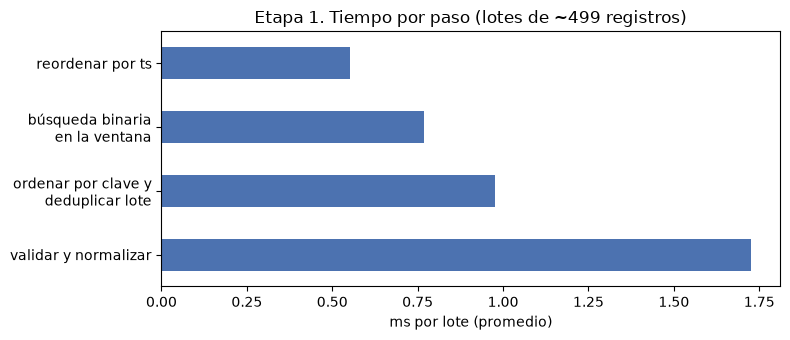

In [14]:
tiempos_pasos = pd.Series(preprocesador.tiempos).rename({
    "validar_normalizar": "validar y normalizar",
    "ordenar_dedup_lote": "ordenar por clave y\ndeduplicar lote",
    "dedup_ventana": "búsqueda binaria\nen la ventana",
    "reordenar_ts": "reordenar por ts",
})
fig, ax = plt.subplots(figsize=(8, 3.5))
(tiempos_pasos * 1000 / m["lotes"]).plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("ms por lote (promedio)")
ax.set_title(f"Etapa 1. Tiempo por paso (lotes de ~{m['entrada'] // m['lotes']} registros)")
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"tiempo_por_paso_{CATEGORIA}.png", dpi=150)
plt.show()

## Paso 9. Experimentos de complejidad

### Diseño del experimento

Se hacen tres experimentos, uno por cada herramienta de la etapa. En cada uno se compara el método propio con líneas base.

| Experimento | Método propio | Líneas base | Complejidad esperada |
| --- | --- | --- | --- |
| A. Ordenar n números reales | `merge_sort` | `sorted()` (Timsort, en C) | O(n log n) |
| B. 1 000 búsquedas en un arreglo ordenado de n enteros | `busqueda_binaria_izq` | `bisect.bisect_left` (en C) y búsqueda lineal | O(log n) por consulta, frente a O(n) de la lineal |
| C. Deduplicar n claves con un 5 % de repeticiones | `merge_sort` y recorrido | `sorted()` y recorrido, y `set()` | O(n log n), frente a O(n) esperado de `set()` |

Los métodos propios se importan de `src/etapa_1/preprocess.py`, el mismo código que ejecuta la etapa en el paso 8. El arreglo del experimento B representa la ventana de claves, y la proporción de repeticiones del experimento C es parecida a la que inyecta la etapa 0. El experimento C compara solo claves idénticas; en la etapa se usa ordenar y recorrer porque admite la tolerancia de tiempo del paso 5, cosa que un `set()` no puede hacer.

**Tamaños y repeticiones.**

- **De 1K a 1M.** 100 repeticiones por tamaño y por método.
- **10M.** Una corrida única por método, en tiempo y en memoria. La celda correspondiente reporta el tiempo medido y lo que tardarían 100 repeticiones, que es la justificación de no repetirla.

**Condiciones de medición.**

- **Reloj.** `time.perf_counter`, con el recolector de basura desactivado durante cada medición.
- **Datos.** Se generan con la semilla 42 antes de medir. En cada tamaño, todos los métodos de un experimento reciben los mismos datos.
- **Memoria.** Se mide con `tracemalloc` en una pasada aparte, porque el rastreo hace más lento el código. Solo se rastrea el método, no la generación de los datos. La memoria actual es la que sigue ocupada al terminar, con el resultado todavía referenciado: la lista ordenada en A y la lista de claves únicas en C; en B las consultas no guardan nada. La memoria pico es el máximo durante la ejecución. Se hace una medición por tamaño y método, porque las asignaciones de memoria no varían entre repeticiones.
- **Plataforma y semilla.** Las del paso 1.
- **Resultados.** Se guardan en `results/etapa_1/complejidad_*.csv` y se reutilizan si existen. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [15]:
REEJECUTAR_EXPERIMENTOS = False
TAMANOS = [1_000, 10_000, 100_000, 1_000_000]
REPETICIONES = 100
N_UNICO = 10_000_000             # corrida única
N_CONSULTAS = 1_000              # consultas por medición en el experimento B
PROPORCION_DUP = 0.05            # repeticiones en el experimento C

ruta_tiempos_exp = CARPETA_RESULTADOS / "complejidad_tiempos.csv"
ruta_memoria_exp = CARPETA_RESULTADOS / "complejidad_memoria.csv"
ruta_exp_10m = CARPETA_RESULTADOS / "complejidad_10M.csv"


def generar_reales(n):
    rng = random.Random(SEED)
    return [rng.random() for _ in range(n)]


def generar_arreglo_y_consultas(n):
    rng = random.Random(SEED)
    arreglo = list(range(0, 2 * n, 2))                       # n valores pares ordenados
    consultas = [rng.randrange(0, 2 * n) for _ in range(N_CONSULTAS)]
    return arreglo, consultas


def generar_claves_con_duplicados(n):
    rng = random.Random(SEED)
    n_unicas = int(n * (1 - PROPORCION_DUP))
    claves = [rng.getrandbits(48) for _ in range(n_unicas)]
    claves += [rng.choice(claves) for _ in range(n - n_unicas)]   # repeticiones
    rng.shuffle(claves)
    return claves


def busqueda_lineal_izq(arreglo, x):
    """Primera posición i con arreglo[i] >= x, revisando uno por uno. O(n)."""
    for i, valor in enumerate(arreglo):
        if valor >= x:
            return i
    return len(arreglo)


def consultas_con(buscar):
    """Función que resuelve todas las consultas del experimento B con el método buscar."""
    def resolver(datos):
        arreglo, consultas = datos
        for x in consultas:
            buscar(arreglo, x)
    return resolver


def quitar_adyacentes(ordenadas):
    unicas = []
    for k in ordenadas:
        if not unicas or k != unicas[-1]:
            unicas.append(k)
    return unicas


def dedup_set(claves):
    vistas = set()
    unicas = []
    for k in claves:
        if k not in vistas:
            vistas.add(k)
            unicas.append(k)
    return unicas


# experimento: (generador de datos, {método: función que recibe los datos})
EXPERIMENTOS = {
    "A. ordenación": (generar_reales, {
        "merge_sort (propio)": merge_sort,
        "sorted() (Timsort, C)": sorted}),
    "B. búsqueda": (generar_arreglo_y_consultas, {
        "búsqueda binaria (propia)": consultas_con(busqueda_binaria_izq),
        "bisect_left (C)": consultas_con(bisect.bisect_left),
        "búsqueda lineal": consultas_con(busqueda_lineal_izq)}),
    "C. deduplicación": (generar_claves_con_duplicados, {
        "merge_sort + recorrido (propio)": lambda claves: quitar_adyacentes(merge_sort(claves)),
        "sorted() + recorrido": lambda claves: quitar_adyacentes(sorted(claves)),
        "set() (tabla hash)": dedup_set}),
}


def medir_tiempo(funcion, datos):
    """Segundos de funcion(datos) con el recolector de basura desactivado."""
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        funcion(datos)
        return time.perf_counter() - t0
    finally:
        gc.enable()


def medir_memoria(funcion, datos):
    """(memoria actual al terminar, con el resultado todavía referenciado; memoria pico), en bytes."""
    gc.collect()
    tracemalloc.start()
    resultado = funcion(datos)
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    del resultado
    return actual, pico


def ns_por_operacion(tabla, columna):
    """Tiempo por elemento en A y C, y por consulta en B, en nanosegundos."""
    operaciones = np.where(tabla["experimento"].str.startswith("B"), N_CONSULTAS, tabla["n"])
    return tabla[columna] / operaciones * 1e9


# Los métodos de cada experimento deben dar el mismo resultado
reales = generar_reales(10_000)
assert merge_sort(reales) == sorted(reales)
arreglo, consultas = generar_arreglo_y_consultas(10_000)
assert all(busqueda_binaria_izq(arreglo, x) == bisect.bisect_left(arreglo, x) == busqueda_lineal_izq(arreglo, x)
           for x in consultas)
claves = generar_claves_con_duplicados(10_000)
assert len({tuple(sorted(f(claves))) for f in EXPERIMENTOS["C. deduplicación"][1].values()}) == 1
del reales, arreglo, consultas, claves
print("Los métodos de cada experimento dan el mismo resultado.")

Los métodos de cada experimento dan el mismo resultado.


### Tiempo de 1K a 1M

La columna `ns_por_operacion` es el tiempo por elemento en A y C, y por consulta en B.

In [16]:
if ruta_tiempos_exp.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_exp = pd.read_csv(ruta_tiempos_exp)
    print(f"Resultados leídos de {ruta_tiempos_exp.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS:
        for experimento, (generar, metodos) in EXPERIMENTOS.items():
            datos = generar(n)
            for metodo, funcion in metodos.items():
                for rep in range(REPETICIONES):
                    filas.append({"experimento": experimento, "metodo": metodo, "n": n, "repeticion": rep,
                                  "segundos": medir_tiempo(funcion, datos)})
            del datos
        print(f"n = {n:>9,} medido")
    tiempos_exp = pd.DataFrame(filas)
    tiempos_exp.to_csv(ruta_tiempos_exp, index=False)

resumen_exp = (tiempos_exp.groupby(["experimento", "metodo", "n"])["segundos"]
               .agg(promedio_s="mean", desv_est_s="std", repeticiones="count").reset_index())
resumen_exp["ns_por_operacion"] = ns_por_operacion(resumen_exp, "promedio_s")
resumen_exp.round({"promedio_s": 6, "desv_est_s": 6, "ns_por_operacion": 1})

n =     1,000 medido
n =    10,000 medido
n =   100,000 medido
n = 1,000,000 medido


,experimento,metodo,n,promedio_s,desv_est_s,repeticiones,ns_por_operacion
0,A. ordenación,merge_sort (propio),1000,0.001217,0.000076,100,1216.5
1,A. ordenación,merge_sort (propio),10000,0.015447,0.000333,100,1544.7
2,A. ordenación,merge_sort (propio),100000,0.208559,0.006084,100,2085.6
3,A. ordenación,merge_sort (propio),1000000,3.053636,0.242755,100,3053.6
4,A. ordenación,"sorted() (Timsort, C)",1000,0.000081,0.000006,100,80.9
5,A. ordenación,"sorted() (Timsort, C)",10000,0.000936,0.000030,100,93.6
6,A. ordenación,"sorted() (Timsort, C)",100000,0.011829,0.000375,100,118.3
7,A. ordenación,"sorted() (Timsort, C)",1000000,0.159395,0.004293,100,159.4
8,B. búsqueda,bisect_left (C),1000,0.000137,0.000031,100,137.0
9,B. búsqueda,bisect_left (C),10000,0.000189,0.000018,100,189.5


### Memoria actual y pico de 1K a 1M

La tabla muestra los bytes por elemento. En B la memoria de las consultas no depende de n, así que por elemento tiende a 0; el CSV guarda los valores absolutos.

In [17]:
if ruta_memoria_exp.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria_exp = pd.read_csv(ruta_memoria_exp)
    print(f"Resultados leídos de {ruta_memoria_exp.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS:
        for experimento, (generar, metodos) in EXPERIMENTOS.items():
            datos = generar(n)
            for metodo, funcion in metodos.items():
                actual, pico = medir_memoria(funcion, datos)
                filas.append({"experimento": experimento, "metodo": metodo, "n": n,
                              "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
            del datos
        print(f"n = {n:>9,} medido")
    memoria_exp = pd.DataFrame(filas)
    memoria_exp.to_csv(ruta_memoria_exp, index=False)

memoria_exp["bytes_por_elemento_actual"] = memoria_exp["actual_mb"] * 1e6 / memoria_exp["n"]
memoria_exp["bytes_por_elemento_pico"] = memoria_exp["pico_mb"] * 1e6 / memoria_exp["n"]
memoria_exp.pivot(index=["experimento", "metodo"], columns="n",
                  values=["bytes_por_elemento_actual", "bytes_por_elemento_pico"]).round(1)

n =     1,000 medido
n =    10,000 medido
n =   100,000 medido
n = 1,000,000 medido


bytes_por_elemento_actual  \
n                                                                  1000      
experimento      metodo                                                      
A. ordenación    merge_sort (propio)                                  66.1   
                 sorted() (Timsort, C)                                 8.0   
B. búsqueda      bisect_left (C)                                       0.0   
                 búsqueda binaria (propia)                             0.0   
                 búsqueda lineal                                       0.1   
C. deduplicación merge_sort + recorrido (propio)                      65.1   
                 set() (tabla hash)                                    7.8   
                 sorted() + recorrido                                  7.9   

                                                                          \
n                                                10000   100000  1000000   
experimento      metodo                                                    
A. ordenación    merge_sort (propio)                19.9     9.2     8.6   
                 sorted() (Timsort, C)               8.0     8.0     8.0   
B. búsqueda      bisect_left (C)                     0.0     0.0     0.0   
                 búsqueda binaria (propia)           0.1     0.0     0.0   
                 búsqueda lineal                     0.0     0.0     0.0   
C. deduplicación merge_sort + recorrido (propio)    20.0     9.2     8.6   
                 set() (tabla hash)                  8.5     8.0     8.4   
                 sorted() + recorrido                8.5     8.0     8.4   

                                                 bytes_por_elemento_pico  \
n                                                                1000      
experimento      metodo                                                    
A. ordenación    merge_sort (propio)                                83.9   
                 sorted() (Timsort, C)                              12.0   
B. búsqueda      bisect_left (C)                                     0.1   
                 búsqueda binaria (propia)                           0.2   
                 búsqueda lineal                                     0.3   
C. deduplicación merge_sort + recorrido (propio)                    83.9   
                 set() (tabla hash)                                 43.7   
                 sorted() + recorrido                               15.9   

                                                                          
n                                                10000   100000  1000000  
experimento      metodo                                                   
A. ordenación    merge_sort (propio)                81.7    81.3    81.4  
                 sorted() (Timsort, C)              12.0    12.0    12.0  
B. búsqueda      bisect_left (C)                     0.0     0.0     0.0  
                 búsqueda binaria (propia)           0.1     0.0     0.0  
                 búsqueda lineal                     0.0     0.0     0.0  
C. deduplicación merge_sort + recorrido (propio)    81.8    81.3    81.4  
                 set() (tabla hash)                 69.8    69.2    55.6  
                 sorted() + recorrido               16.5    16.0    16.4

### Corrida única con 10M

Se mide una sola vez el tiempo y la memoria de cada método con 10 millones de elementos. La celda reporta cuánto tardarían 100 repeticiones a partir del tiempo medido.

In [18]:
if ruta_exp_10m.exists() and not REEJECUTAR_EXPERIMENTOS:
    exp_10m = pd.read_csv(ruta_exp_10m)
    print(f"Resultados leídos de {ruta_exp_10m.relative_to(RAIZ)}")
else:
    filas = []
    for experimento, (generar, metodos) in EXPERIMENTOS.items():
        datos = generar(N_UNICO)
        for metodo, funcion in metodos.items():
            segundos = medir_tiempo(funcion, datos)
            actual, pico = medir_memoria(funcion, datos)
            filas.append({"experimento": experimento, "metodo": metodo, "n": N_UNICO, "segundos": segundos,
                          "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
            print(f"{metodo} medido")
        del datos
    exp_10m = pd.DataFrame(filas)
    exp_10m.to_csv(ruta_exp_10m, index=False)

exp_10m["ns_por_operacion"] = ns_por_operacion(exp_10m, "segundos")
exp_10m["bytes_por_elemento_actual"] = exp_10m["actual_mb"] * 1e6 / exp_10m["n"]
exp_10m["bytes_por_elemento_pico"] = exp_10m["pico_mb"] * 1e6 / exp_10m["n"]

segundos_corrida = exp_10m["segundos"].sum()
print(f"Una corrida de todos los métodos con 10M: {segundos_corrida / 60:.1f} min de medición.")
print(f"100 repeticiones tomarían unas {100 * segundos_corrida / 3600:.0f} h solo en tiempo, "
      f"sin contar la pasada de memoria.")
exp_10m.round({"segundos": 3, "actual_mb": 1, "pico_mb": 1, "ns_por_operacion": 1,
               "bytes_por_elemento_actual": 1, "bytes_por_elemento_pico": 1})

merge_sort (propio) medido
sorted() (Timsort, C) medido
búsqueda binaria (propia) medido
bisect_left (C) medido
búsqueda lineal medido
merge_sort + recorrido (propio) medido
sorted() + recorrido medido
set() (tabla hash) medido
Una corrida de todos los métodos con 10M: 3.9 min de medición.
100 repeticiones tomarían unas 6 h solo en tiempo, sin contar la pasada de memoria.


,experimento,metodo,n,segundos,actual_mb,pico_mb,ns_por_operacion,bytes_por_elemento_actual,bytes_por_elemento_pico
0,A. ordenación,merge_sort (propio),10000000,45.990,89.2,827.3,4599.0,8.9,82.7
1,A. ordenación,"sorted() (Timsort, C)",10000000,2.218,80.0,120.0,221.8,8.0,12.0
2,B. búsqueda,búsqueda binaria (propia),10000000,0.004,0.0,0.0,3596.9,0.0,0.0
3,B. búsqueda,bisect_left (C),10000000,0.001,0.0,0.0,1465.6,0.0,0.0
4,B. búsqueda,búsqueda lineal,10000000,122.990,0.0,0.0,122990030.0,0.0,0.0
5,C. deduplicación,merge_sort + recorrido (propio),10000000,50.896,79.3,827.3,5089.6,7.9,82.7
6,C. deduplicación,sorted() + recorrido,10000000,8.532,79.2,159.2,853.2,7.9,15.9
7,C. deduplicación,set() (tabla hash),10000000,3.305,79.2,446.6,330.5,7.9,44.7


### Escalabilidad en escala log-log

En una gráfica log-log, un costo de la forma T(n) = c·nᵏ aparece como una recta de pendiente k. Un costo O(n) o O(n log n) da una pendiente cercana a 1 (entre 1.0 y 1.1 para n log n en este rango), y el tiempo total de las 1 000 consultas con búsqueda binaria, O(log n), una pendiente cercana a 0. Las líneas punteadas son las referencias teóricas, ancladas en el primer punto del método indicado. Los puntos huecos son la corrida única con 10M. La pendiente se ajusta con mínimos cuadrados sobre los promedios de 1K a 1M.

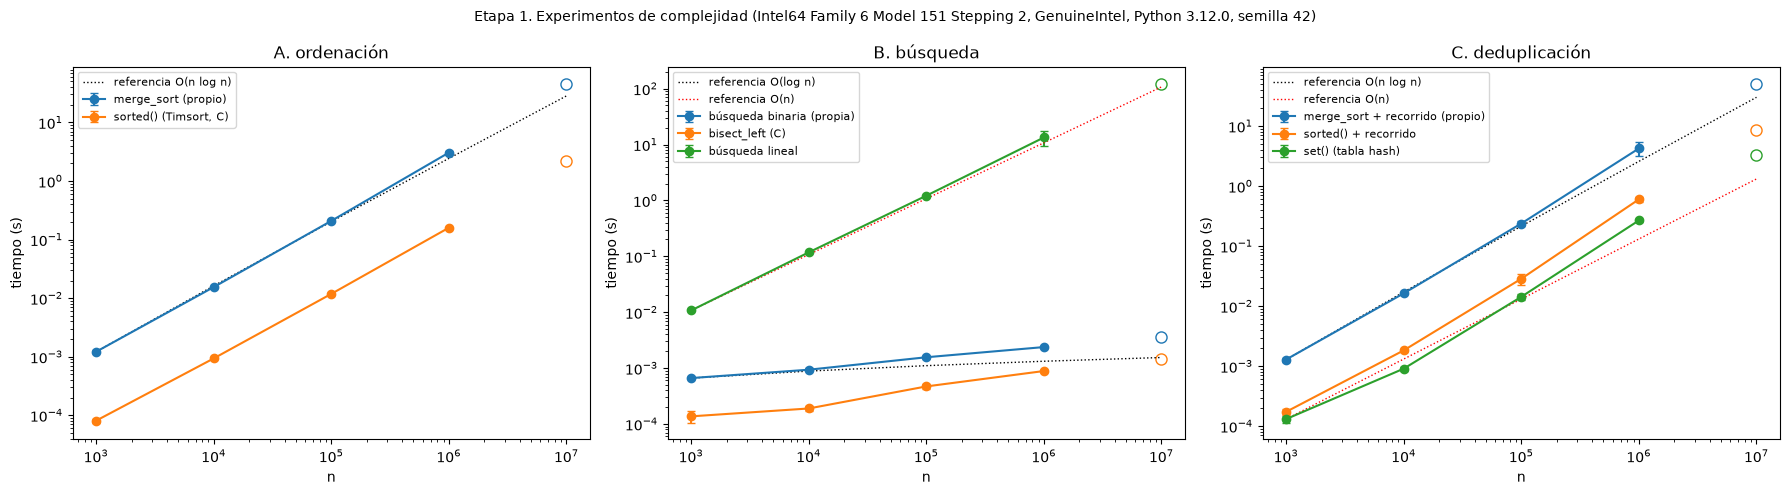

,experimento,metodo,pendiente_empirica,esperado,rango_n
0,A. ordenación,merge_sort (propio),1.13,≈1.0-1.1 (n log n),"1,000 a 1,000,000"
1,A. ordenación,"sorted() (Timsort, C)",1.10,≈1.0-1.1 (n log n),"1,000 a 1,000,000"
2,B. búsqueda,bisect_left (C),0.28,≈0 (log n),"1,000 a 1,000,000"
3,B. búsqueda,búsqueda binaria (propia),0.19,≈0 (log n),"1,000 a 1,000,000"
4,B. búsqueda,búsqueda lineal,1.03,≈1 (n),"1,000 a 1,000,000"
5,C. deduplicación,merge_sort + recorrido (propio),1.17,≈1.0-1.1 (n log n),"1,000 a 1,000,000"
6,C. deduplicación,set() (tabla hash),1.11,≈1 (n),"1,000 a 1,000,000"
7,C. deduplicación,sorted() + recorrido,1.18,≈1.0-1.1 (n log n),"1,000 a 1,000,000"


In [19]:
REFERENCIAS = {    # experimento: [(método donde se ancla, forma de la curva, etiqueta)]
    "A. ordenación": [("merge_sort (propio)", lambda n: n * np.log2(n), "O(n log n)")],
    "B. búsqueda": [("búsqueda binaria (propia)", np.log2, "O(log n)"),
                    ("búsqueda lineal", lambda n: n, "O(n)")],
    "C. deduplicación": [("merge_sort + recorrido (propio)", lambda n: n * np.log2(n), "O(n log n)"),
                         ("set() (tabla hash)", lambda n: n, "O(n)")],
}
TEORICO = {
    "merge_sort (propio)": "≈1.0-1.1 (n log n)", "sorted() (Timsort, C)": "≈1.0-1.1 (n log n)",
    "búsqueda binaria (propia)": "≈0 (log n)", "bisect_left (C)": "≈0 (log n)", "búsqueda lineal": "≈1 (n)",
    "merge_sort + recorrido (propio)": "≈1.0-1.1 (n log n)", "sorted() + recorrido": "≈1.0-1.1 (n log n)",
    "set() (tabla hash)": "≈1 (n)",
}

n_ref = np.array(TAMANOS + [N_UNICO], dtype=float)
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (experimento, (_, metodos)) in zip(ejes, EXPERIMENTOS.items()):
    resumen = resumen_exp[resumen_exp["experimento"] == experimento]
    unico = exp_10m[exp_10m["experimento"] == experimento]
    for metodo in metodos:
        datos = resumen[resumen["metodo"] == metodo]
        barras = ax.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3,
                             label=metodo)
        fila = unico[unico["metodo"] == metodo]
        ax.plot(fila["n"], fila["segundos"], marker="o", markerfacecolor="none", markersize=8, linestyle="none",
                color=barras[0].get_color())
    for (metodo, forma, etiqueta), estilo in zip(REFERENCIAS[experimento], ["k:", "r:"]):
        base = resumen[resumen["metodo"] == metodo].iloc[0]
        ax.plot(n_ref, base["promedio_s"] * forma(n_ref) / forma(base["n"]), estilo, lw=1,
                label=f"referencia {etiqueta}")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel("tiempo (s)"); ax.set_title(experimento.capitalize())
    ax.legend(fontsize=8)
plt.suptitle(f"Etapa 1. Experimentos de complejidad ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, "
             f"semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "complejidad_escalabilidad.png", dpi=150)
plt.show()

pendientes = []
for (experimento, metodo), datos in resumen_exp.groupby(["experimento", "metodo"]):
    k, _ = np.polyfit(np.log10(datos["n"]), np.log10(datos["promedio_s"]), 1)
    pendientes.append({"experimento": experimento, "metodo": metodo, "pendiente_empirica": round(k, 2),
                       "esperado": TEORICO[metodo], "rango_n": f"{datos['n'].min():,} a {datos['n'].max():,}"})
pd.DataFrame(pendientes)

### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/etapa_1/`, con la plataforma del paso 1. En otra máquina cambian los tiempos absolutos, pero no las pendientes ni las conclusiones.

- **A. Ordenación.** `merge_sort` y `sorted()` tienen pendientes de 1.13 y 1.10, coherentes con O(n log n). El tiempo de `merge_sort` dividido entre n·log₂ n se mantiene entre 116 y 126 ns de 1K a 100K, y sube a 153 ns en 1M y a 198 ns en 10M. Con millones de elementos los datos dejan de caber en la caché del procesador y cada acceso a memoria cuesta más; es un efecto de la memoria, no del algoritmo. `sorted()` es entre 15 y 21 veces más rápida porque Timsort está escrito en C, una diferencia de factor constante. Con 10M, `merge_sort` tarda 46 s y `sorted()` 2.2 s.
- **B. Búsqueda.** La búsqueda lineal tiene pendiente 1.03, que corresponde a O(n). La búsqueda binaria propia tiene pendiente 0.19: de 1K a 10M, n crece 10 000 veces y el tiempo por consulta solo pasa de 0.66 a 3.6 µs. Crece algo más que log₂ n, que pasa de 10 a 23, porque en arreglos grandes cada comparación lee una posición lejana que no está en la caché. Con 1M, una consulta lineal tarda 13.4 ms, unas 5 600 veces más que la binaria (2.4 µs), y con 10M la diferencia llega a unas 34 000 veces (123 ms frente a 3.6 µs). `bisect_left` es unas 2.7 veces más rápida que la búsqueda propia en 1M porque está en C, con el mismo crecimiento logarítmico (pendiente 0.28).
- **C. Deduplicación, tiempo.** `set()` es el método más rápido, como predice su costo O(n) esperado. Con 10M tarda 3.3 s, frente a 8.5 s de `sorted()` con recorrido y 51 s de `merge_sort` con recorrido, unas 15 veces más. Las pendientes (1.11 para `set()`, 1.17 y 1.18 para los dos métodos que ordenan) quedan algo por encima de lo esperado por el mismo efecto de caché del experimento A.
- **Memoria de la ordenación.** `merge_sort` llega a un pico de 81 a 83 bytes por elemento desde 10K hasta 10M, es decir, memoria adicional O(n): crea un par (clave, elemento) por cada elemento y listas temporales en cada mezcla. Con 10M el pico es de 827 MB. Al terminar solo queda la lista ordenada, unos 8 bytes por elemento, una referencia. En 1K y 10K la memoria actual por elemento es mayor porque Python conserva una cantidad fija de memoria de los pares ya liberados para reutilizarla, y esa cantidad pesa más cuanto menor es n. `sorted()` usa 8 bytes por elemento al terminar y 12 de pico, por el espacio auxiliar de Timsort.
- **Memoria de la deduplicación.** `sorted()` con recorrido tiene un pico de unos 16 bytes por elemento (la lista ordenada y la de únicos) y `set()` de 44 a 70, porque la tabla hash reserva espacio libre y crece duplicando su tamaño. `merge_sort` con recorrido tiene el mismo pico que `merge_sort`. Los tres terminan con la lista de claves únicas, unos 8 bytes por elemento.
- **Memoria de la búsqueda.** Las consultas no guardan nada y su pico no depende de n: 76 bytes con `bisect_left` y 208 bytes con la búsqueda binaria propia en la mayoría de los tamaños (1.5 KB como máximo). La búsqueda binaria usa memoria adicional O(1); la única memoria que ocupa la ventana de la etapa es su arreglo ordenado, O(w).

Los tres métodos propios cumplen la complejidad esperada. Las líneas base en C son más rápidas por un factor constante, y `set()` es además mejor en orden para claves idénticas, pero no admite la tolerancia de tiempo que necesita la etapa. En la etapa cada lote tiene unos 500 eventos (log₂ 500 ≈ 9) y la ventana no pasa de 683 entradas, así que el factor log n y la memoria O(b) de `merge_sort` son pequeños. A cambio de ese costo, ordenar y recorrer admite la tolerancia de tiempo de los reintentos y deja el lote ordenado para la mezcla con la ventana.

## Paso 10. Salida de la etapa 1 para la etapa 2

La salida queda en `data/interim/<CATEGORIA>/`. Los lotes limpios ya se escribieron en el paso 8, a medida que salían de la etapa; aquí se guardan los rechazados y las métricas, y se comprueba el archivo de lotes. El notebook de la etapa 2 los leerá lote por lote para asignar prioridades.

| Archivo | Contenido | Lo usa |
| --- | --- | --- |
| `etapa1_lotes.jsonl` | Una línea por lote con sus eventos limpios en el formato `Event` | Etapa 2 |
| `etapa1_rechazados.jsonl` | Una línea por registro rechazado con su motivo | Auditoría |
| `etapa1_metricas.json` | Conteos de entrada, salida, rechazos y duplicados, y desorden al entrar y al salir | Informe |

In [20]:
ruta_rechazados = CARPETA_INTERIM / "etapa1_rechazados.jsonl"
with open(ruta_rechazados, "w", encoding="utf-8") as archivo:
    nodo = preprocesador.rechazados._cabeza
    while nodo is not None:
        motivo, registro = nodo.valor
        archivo.write(json.dumps({"motivo": motivo, "registro": registro}) + "\n")
        nodo = nodo.siguiente

metricas_salida = {**dict(preprocesador.metricas), "rechazos_por_motivo": dict(preprocesador.motivos),
                   "segundos_por_paso": dict(preprocesador.tiempos),
                   "desorden_entrada": desorden_entrada, "desorden_salida": desorden_salida,
                   "duracion_lote_mediana_s": duracion_lote_mediana_s,
                   "categoria": CATEGORIA, "n_resenas": inyecciones["n_resenas"],
                   "porcentaje_tardios": config.PORCENTAJE_TARDIOS,
                   "retraso_max_tardios_s": config.RETRASO_MAX_TARDIOS_S,
                   "ventana_s": VENTANA_S, "tolerancia_s": TOLERANCIA_S, "semilla": SEED}
(CARPETA_INTERIM / "etapa1_metricas.json").write_text(json.dumps(metricas_salida, indent=2), encoding="utf-8")

# Verificación: se relee la salida y se reconstruyen los eventos
total = lotes_salida = 0
with open(RUTA_SALIDA, encoding="utf-8") as archivo:
    for linea in archivo:
        eventos = [Event(**d) for d in json.loads(linea)["eventos"]]
        total += len(eventos)
        lotes_salida += 1
assert total == preprocesador.metricas["salida"]
print(f"{RUTA_SALIDA.relative_to(RAIZ)}: {total:,} eventos en {lotes_salida:,} lotes "
      f"({RUTA_SALIDA.stat().st_size / 1e9:.2f} GB)")
print(f"{ruta_rechazados.relative_to(RAIZ)}: {len(preprocesador.rechazados):,} registros rechazados")

data\interim\Office_Products\etapa1_lotes.jsonl: 9,940,617 eventos en 21,025 lotes (3.49 GB)
data\interim\Office_Products\etapa1_rechazados.jsonl: 98,781 registros rechazados


## Resumen de la etapa 1

| Aspecto | Decisión |
| --- | --- |
| Validación | Reglas por campo y por tipo de evento; los inválidos van a una `ColaEnlazada` de rechazados con su motivo |
| Normalización | `ts` de ms a s, precio a `float`, `user_id` y `parent_asin` en mayúsculas, categoría canónica, búsqueda en minúsculas |
| Ordenación | `merge_sort` propio, O(n log n) garantizado y estable |
| Duplicados en el lote | Ordenar por (clave, ts) y recorrer, con tolerancia de 1 s, en O(b log b) |
| Duplicados entre lotes | Ventana ordenada de 10 minutos con búsqueda binaria propia, O(log w) por evento y O(w + b) de actualización por lote |
| Orden temporal | Reordenación por `ts` dentro de cada lote; el desorden entre lotes queda acotado a los eventos que llegan más tarde que su lote |
| Salida | Lotes de `Event` en `data/interim/<CATEGORIA>/etapa1_lotes.jsonl` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 2. Bloom, B. H. (1970). Space/time trade-offs in hash coding with allowable errors. *Communications of the ACM*, 13(7), 422-426.